In [35]:
from tensorflow.keras.models import Model 

from tensorflow.keras.layers import Input, Conv2D, Conv2DTranspose, UpSampling2D, Dropout

import numpy as np 

import matplotlib.pyplot as plt 

In [36]:
input_layer = Input(shape=(28, 28, 1))

In [37]:
conv_layer = Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same')(input_layer) 

transpose_conv_layer = Conv2DTranspose(filters=1, kernel_size=(3, 3), activation='sigmoid', padding='same')(conv_layer) 


In [38]:
model = Model(inputs=input_layer, outputs=transpose_conv_layer)

In [39]:
model.compile(optimizer='adam', loss='mean_squared_error')

In [40]:
# Generate synthetic training data 

X_train = np.random.rand(1000, 28, 28, 1) 

y_train = X_train # For reconstruction, the target is the input 

history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.2) 

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0716 - val_loss: 0.0572
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0445 - val_loss: 0.0320
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0237 - val_loss: 0.0161
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0119 - val_loss: 0.0084
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0067 - val_loss: 0.0053
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0046 - val_loss: 0.0040
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0036 - val_loss: 0.0033
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0031 - val_loss: 0.0029
Epoch 9/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0027 - val_loss: 0.0025
Epoch 10/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0024 - val_loss: 0.0023


In [41]:
 # Generate synthetic test data 

X_test = np.random.rand(200, 28, 28, 1) 

y_test = X_test 

loss = model.evaluate(X_test, y_test) 

print(f'Test loss: {loss}')

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0023
Test loss: 0.0022559945937246084


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


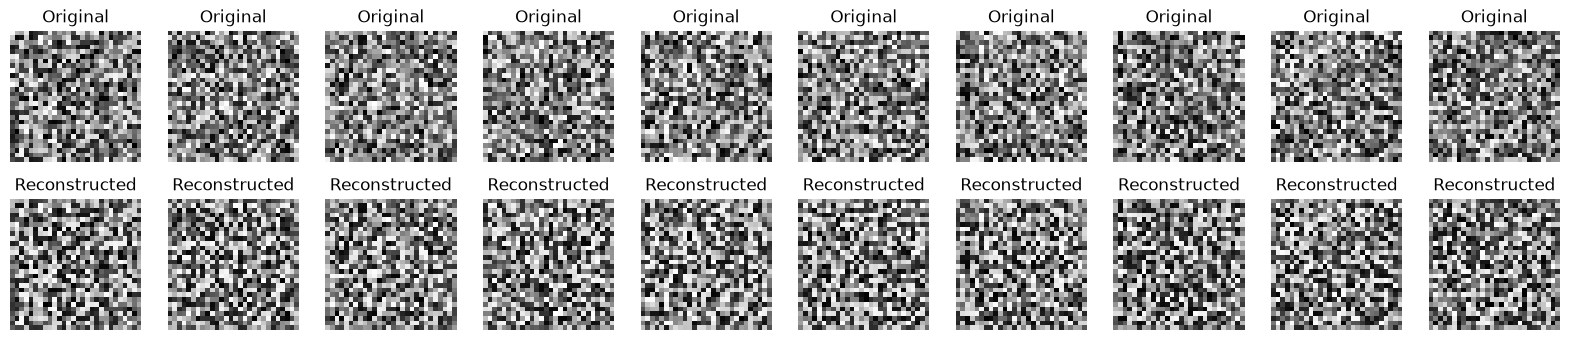

In [42]:
# Predict on test data 
y_pred = model.predict(X_test) 

# Plot some sample images 

n = 10 # Number of samples to display 

plt.figure(figsize=(20, 4))

for i in range(n): 

    # Display original 
    ax = plt.subplot(2, n, i + 1) 
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original") 
    plt.axis('off') 
    # Display reconstruction 
    ax = plt.subplot(2, n, i + 1 + n) 
    plt.imshow(y_pred[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.show() 

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1420 - val_loss: 0.0680
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0659 - val_loss: 0.0350
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0376 - val_loss: 0.0166
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0248 - val_loss: 0.0099
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0194 - val_loss: 0.0073
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0168 - val_loss: 0.0062
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0153 - val_loss: 0.0055
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0142 - val_loss: 0.0052
Epoch 9/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0133 - val_loss: 0.0049
Epoch 10/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0127 - val_loss: 0.0047
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0047
Test loss: 0.004675804637372494
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


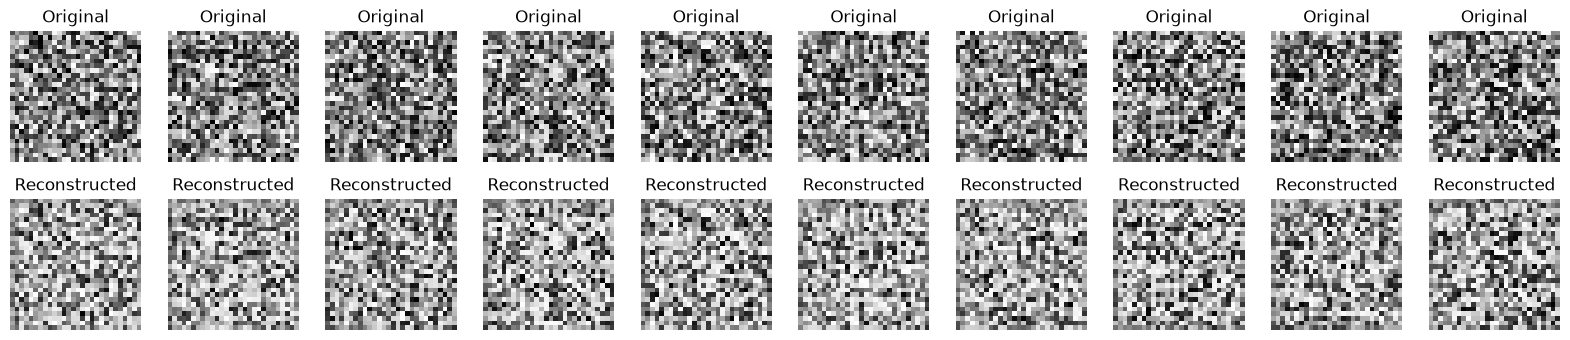

In [43]:
input_layer = Input(shape=(28, 28, 1))

conv_layer = Conv2D(filters=32, kernel_size=(4, 4), activation='tanh', padding='same')(input_layer) 

dropout_layer = Dropout(0.5)(conv_layer)

transpose_conv_layer = Conv2DTranspose(filters=1, kernel_size=(4, 4), activation='tanh', padding='same')(dropout_layer) 

model = Model(inputs=input_layer, outputs=transpose_conv_layer)

model.compile(optimizer='adam', loss='mean_squared_error')

# Generate synthetic training data 

X_train = np.random.rand(1000, 28, 28, 1) 

y_train = X_train # For reconstruction, the target is the input 

history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.2) 

 # Generate synthetic test data 

X_test = np.random.rand(200, 28, 28, 1) 

y_test = X_test 

loss = model.evaluate(X_test, y_test) 

print(f'Test loss: {loss}')

# Predict on test data 
y_pred = model.predict(X_test) 

# Plot some sample images 

n = 10 # Number of samples to display 

plt.figure(figsize=(20, 4))

for i in range(n): 

    # Display original 
    ax = plt.subplot(2, n, i + 1) 
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original") 
    plt.axis('off') 
    # Display reconstruction 
    ax = plt.subplot(2, n, i + 1 + n) 
    plt.imshow(y_pred[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.show() 

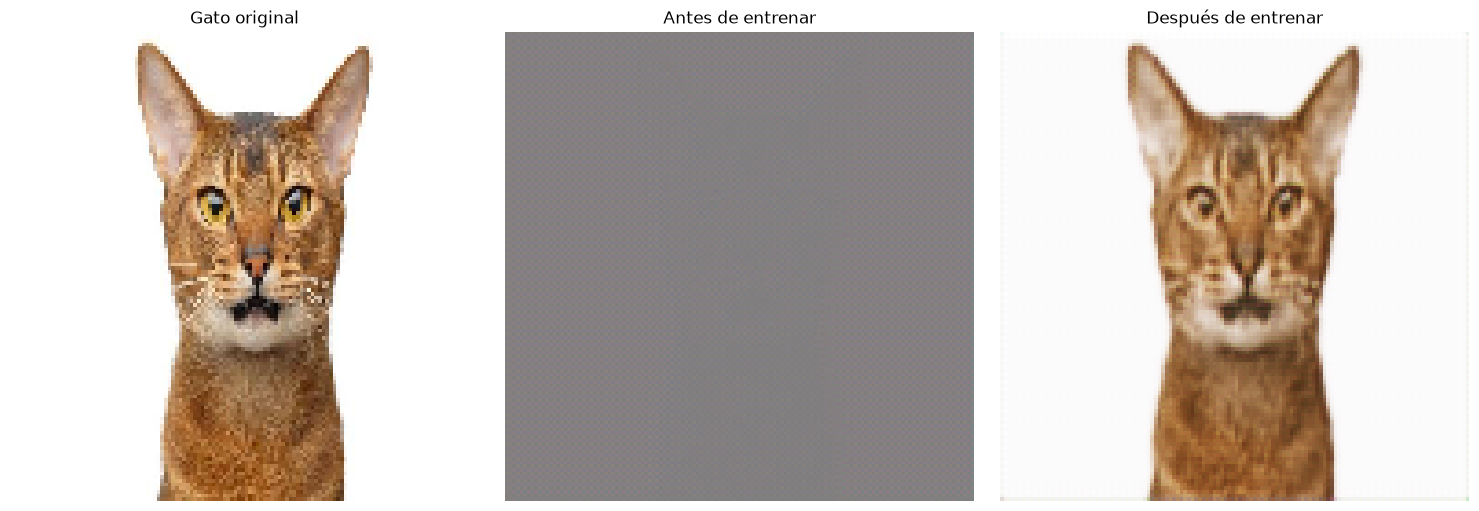

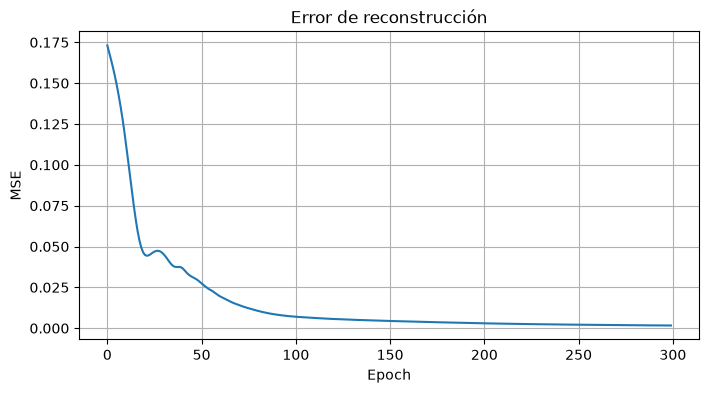

In [52]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.layers import Input, Conv2D, Conv2DTranspose
from tensorflow.keras.models import Model
from tensorflow.keras.utils import load_img, img_to_array

# ==========================================
# 1. CARGAR IMAGEN DEL GATO
# ==========================================

imagen = load_img("image.png", target_size=(128, 128))
imagen = img_to_array(imagen) / 255.0

imagen_input = np.expand_dims(imagen, axis=0)

# ==========================================
# 2. CREAR AUTOENCODER
# ==========================================

input_layer = Input(shape=(128, 128, 3))

# ENCODER
x = Conv2D(
    filters=32,
    kernel_size=3,
    strides=2,
    activation="relu",
    padding="same"
)(input_layer)

# DECODER
x = Conv2DTranspose(
    filters=32,
    kernel_size=3,
    strides=2,
    activation="relu",
    padding="same"
)(x)

output_layer = Conv2DTranspose(
    filters=3,
    kernel_size=3,
    activation="sigmoid",
    padding="same"
)(x)

model = Model(input_layer, output_layer)

# ==========================================
# 3. COMPILAR MODELO
# ==========================================

model.compile(
    optimizer="adam",
    loss="mse"
)

# ==========================================
# 4. IMAGEN ANTES DE ENTRENAR
# ==========================================

antes = model.predict(imagen_input, verbose=0)

# ==========================================
# 5. ENTRENAR MODELO
# ==========================================

historial = model.fit(
    imagen_input,
    imagen_input,
    epochs=300,
    verbose=0
)

# ==========================================
# 6. IMAGEN DESPUÉS DE ENTRENAR
# ==========================================

despues = model.predict(imagen_input, verbose=0)

# ==========================================
# 7. GRAFICAR RESULTADOS
# ==========================================

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagen)
plt.title("Gato original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(antes[0])
plt.title("Antes de entrenar")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(despues[0])
plt.title("Después de entrenar")
plt.axis("off")

plt.tight_layout()
plt.show()

# ==========================================
# 8. GRAFICAR ERROR
# ==========================================

plt.figure(figsize=(8, 4))
plt.plot(historial.history["loss"])
plt.title("Error de reconstrucción")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.grid(True)
plt.show()